**1. Environment set-up**

In [ ]:
# 1. Load Dataset
!gdown https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/000/940/original/netflix.csv

Downloading...
From: https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/000/940/original/netflix.csv
To: /content/netflix.csv
100% 3.40M/3.40M [00:00<00:00, 36.5MB/s]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset and format dates
df = pd.read_csv("netflix.csv")
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['added_month'] = df['date_added'].dt.month_name()
df['added_day'] = df['date_added'].dt.day_name()

# Sample data visualization
df.sample(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_month,added_day
6400,s6401,Movie,Caida del Cielo,Néstor Sánchez Sotelo,"Muriel Santa Ana, Peto Menahem, Héctor Díaz, S...",Argentina,2017-01-20,2016,TV-MA,78 min,"Comedies, International Movies, Romantic Movies",When Julia literally falls into Alejandro's ba...,January,Friday
7515,s7516,Movie,Movie 43,"Peter Farrelly, Will Graham, Steve Carr, Griff...","Greg Kinnear, Dennis Quaid, Common, Seth MacFa...",United States,2019-04-09,2013,R,94 min,Comedies,An eye-popping cast stars in this sketch-comed...,April,Tuesday
7889,s7890,Movie,Room,Lenny Abrahamson,"Brie Larson, Jacob Tremblay, Joan Allen, Sean ...","Ireland, Canada, United Kingdom, United States",2018-07-19,2015,R,118 min,"Dramas, Independent Movies","Kidnapped, confined to a tiny room and raped, ...",July,Thursday
1475,s1476,Movie,Too Handsome to Handle,Sabrina Rochelle Kalangie,"Ari Irham, Nikita Willy, Calvin Jeremy, Rachel...",Indonesia,2020-12-31,2019,TV-14,106 min,"Comedies, Dramas, International Movies",Wary of the effects of his good looks on other...,December,Thursday
8320,s8321,Movie,The Girl with the Dragon Tattoo,David Fincher,"Daniel Craig, Rooney Mara, Christopher Plummer...","United States, Sweden, Norway",2021-01-05,2011,R,158 min,"Dramas, Thrillers",When a young computer hacker is tasked with in...,January,Tuesday


**2. Sub Questions 1 & 7: What Type of Content is Available in Different Countries?**

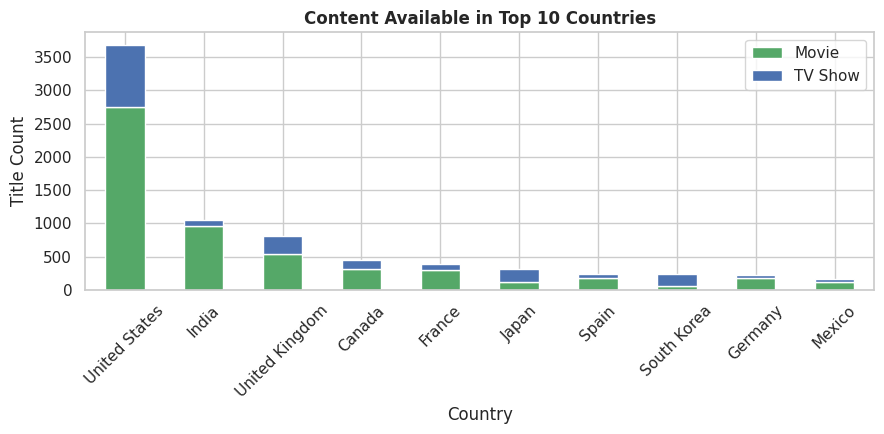

type,Movie,TV Show
country,,
United States,2751,938
India,962,84
United Kingdom,532,272
Canada,319,126
France,303,90
Japan,119,199
Spain,171,61
South Korea,61,170
Germany,182,44


In [ ]:
# Unnest countries and find top 10
df_country = df.assign(country=df['country'].dropna().str.split(', ')).explode('country')
top10_c = df_country['country'].value_counts().head(10).index
df_top_c = df_country[df_country['country'].isin(top10_c)]

# Stacked bar plot using colors Green & Blue
ct = pd.crosstab(df_top_c['country'], df_top_c['type']).loc[top10_c]
ct.plot(kind='bar', stacked=True, color=['g', 'b'], figsize=(9, 4.5))
plt.title('Content Available in Top 10 Countries', fontsize=12, fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Title Count')
plt.xticks(rotation=45)
plt.legend(['Movie', 'TV Show'])
plt.tight_layout()
plt.show()

# Display summary table
display(ct)

**Analytical Findings & Business Takeaways**

***1. Content Volume:*** The United States leads with 3,690 titles (2,752 Movies, 938 TV Shows), followed by India with 1,046 titles and the UK with 806 titles.

***2. Regional Preferences:***

*   India is heavily skewed toward Movies (962 movies ; 92.0%) over TV Shows (84 TV Shows), dominated by International Movies and Dramas.
*   Japan (199 TV Shows vs. 119 Movies) and South Korea (170 TV Shows vs. 61 Movies) are predominantly TV Show-first markets, dominated by Anime Series and Korean TV Shows.

***3. Business Recommendation:*** Netflix requires a tailored content approach to its major stakeholder countries. For instance, In India, acquire local theatrical streaming rights and direct-to-digital films. Similarly, in East Asia (Japan/South Korea), Netflix may invest primarily on episodic dramas and anime productions.

**3. Sub Question 2: How Has the Number of Movies Released per Year Changed Over the Last 20–30 Years?**

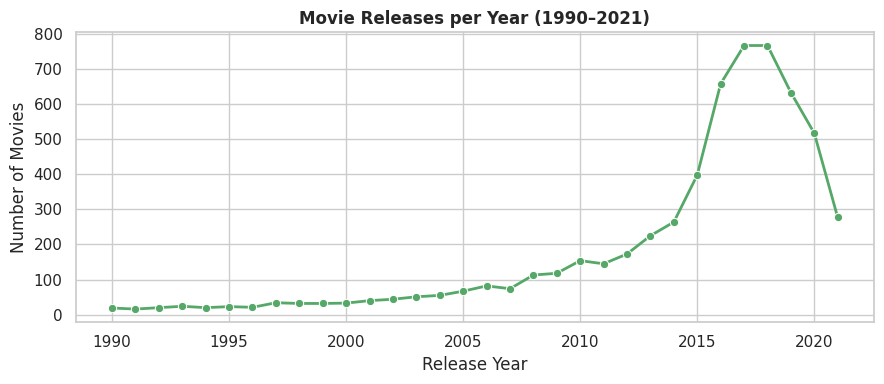

In [ ]:
# Filter movies released from 1990 onwards
movies_yearly = df[(df['type'] == 'Movie') & (df['release_year'] >= 1990)]['release_year'].value_counts().sort_index()

plt.figure(figsize=(9, 4))
sns.lineplot(x=movies_yearly.index, y=movies_yearly.values, color='g', marker='o', linewidth=2)
plt.title('Movie Releases per Year (1990–2021)', fontsize=12, fontweight='bold')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.show()

**Analytical Findings & Business Takeaways**

***1. Exponential Growth (2008–2018):*** The total number of movies grew from 74 in 2007 to 264 in 2014, accelerating after Netflix's original content pivot to peak at 767 movies each in both 2017 and 2018.

***2.Post-2018 Contraction:*** Movie additions declined to 633 in 2019, 517 in 2020, and 277 in 2021.

***3. Business Recommendation:*** The decline after 2018 may be attributed to high-budget original productions and episodic series. Netflix should maintain quality over quantity in feature films while expanding the list of evergreen classics.

**4. Sub Question 3: Comparison of TV Shows vs. Movies**



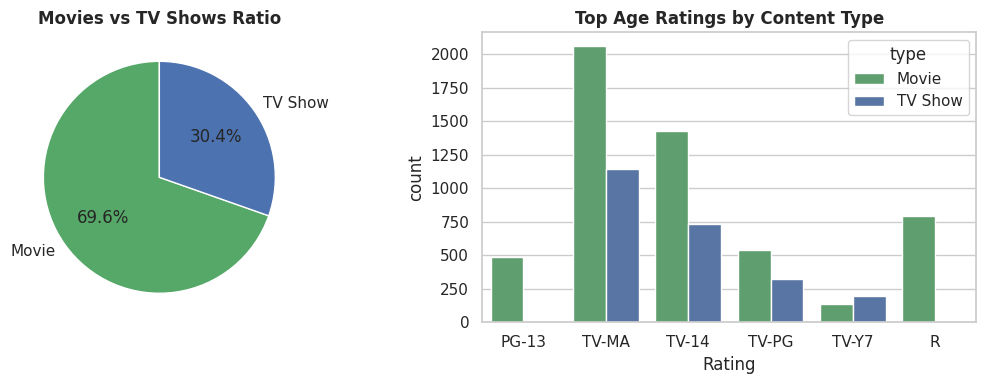

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Proportions pie chart
type_counts = df['type'].value_counts()
axes[0].pie(type_counts, labels=type_counts.index, autopct='%.1f%%', colors=['g', 'b'], startangle=90)
axes[0].set_title('Movies vs TV Shows Ratio', fontweight='bold')

# 2. Rating distribution
top_ratings = df['rating'].value_counts().head(6).index
sns.countplot(data=df[df['rating'].isin(top_ratings)], x='rating', hue='type', palette=['g', 'b'], ax=axes[1])
axes[1].set_title('Top Age Ratings by Content Type', fontweight='bold')
axes[1].set_xlabel('Rating')

plt.tight_layout()
plt.show()

**Analytical Findings & Business Takeaways**

***1. Catalog Makeup:*** The catalog consists of 6,131 Movies (69.6%) and 2,676 TV Shows (30.4%).

***2.Audience Targeting:*** Both categories are dominated by TV-MA (mature adults) and TV-14 (teens/adults) ratings, showing a distinct content focus on older teenage and adult subscribers.

***3.Duration:*** Average movie length is ~99.6 minutes (median: 98 minutes), with 50% falling between 87 and 114 minutes.Over 67% of TV Shows (1,793 titles) only have 1 season, indicating a high churn/cancellation rate after season one.

**Sub-Question 4: What is the Best Time to Launch a TV Show?**

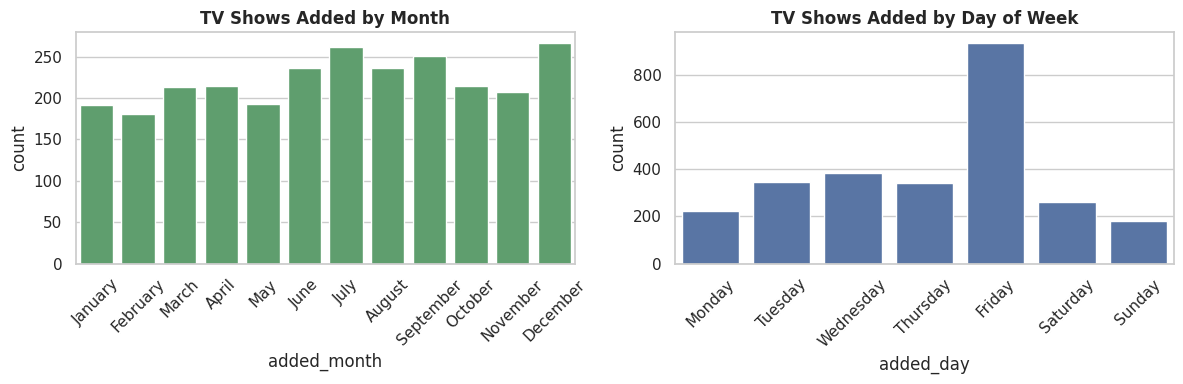

In [ ]:
tv = df[df['type'] == 'TV Show']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
sns.countplot(data=tv, x='added_month', order=months, color='g', ax=axes[0])
axes[0].set_title('TV Shows Added by Month', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=tv, x='added_day', order=days, color='b', ax=axes[1])
axes[1].set_title('TV Shows Added by Day of Week', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

***Analytical Findings & Business Takeaways***


***1. Binge Day:*** As we see in the graph, Friday is the dominant release day (932 TV Shows, representing 35% of all TV releases). This aligns with consumer binge-watching behavior heading into the weekend. Wednesday (382) and Tuesday (345) follow.

***2. Best Months:*** December (266), July (262), and September (251) see the highest release volume-presummably attributed to winter holidays and mid-summer vacations in the Global north.

***3. Business Recommendation:*** It may be advised to launch original series on Fridays in early December or July. Mid-tier series should be scheduled on Wednesdays/Thursdays in lower-volume months (February, May) to prevent viewership.

**Sub Question 5: Analysis of Actors & Directors of Different Types of Shows/Movies**

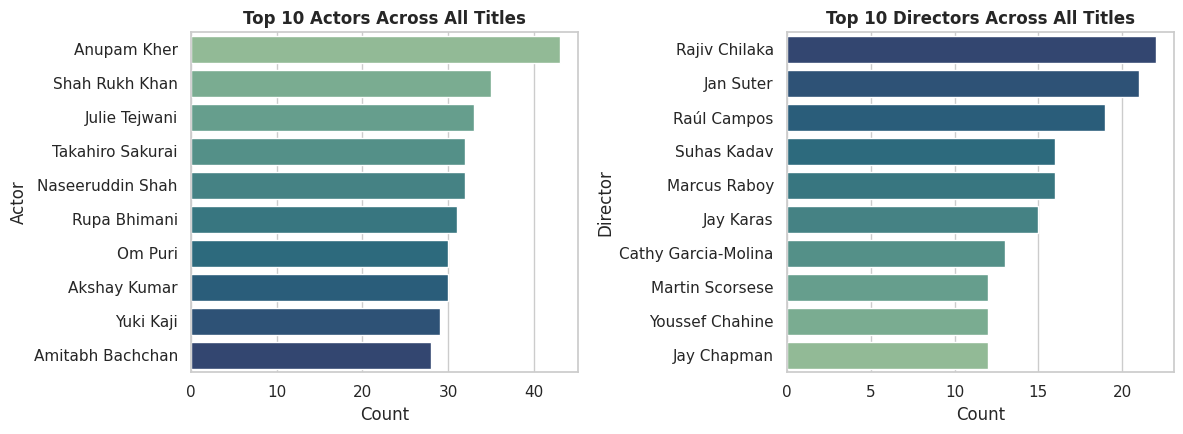

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Top 10 Actors
top_actors = df['cast'].dropna().str.split(', ').explode().value_counts().head(10).reset_index()
top_actors.columns = ['Actor', 'Count']
sns.barplot(data=top_actors, x='Count', y='Actor', hue='Actor', legend=False, palette='crest', ax=axes[0])
axes[0].set_title('Top 10 Actors Across All Titles', fontweight='bold')

# Top 10 Directors
top_dirs = df['director'].dropna().str.split(', ').explode().value_counts().head(10).reset_index()
top_dirs.columns = ['Director', 'Count']
sns.barplot(data=top_dirs, x='Count', y='Director', hue='Director', legend=False, palette='crest_r', ax=axes[1])
axes[1].set_title('Top 10 Directors Across All Titles', fontweight='bold')

plt.tight_layout()
plt.show()

***Analytical Findings & Business Takeaways***

***1.Movie Cast:*** To my surprise, Indian actors dominate the top movie spots: Anupam Kher (42 movies), Shah Rukh Khan (35), Naseeruddin Shah (32), and Akshay Kumar (30).

***2.TV Show Cast:*** Top television cast members are heavily concentrated in Japanese voice talent (e.g., Takahiro Sakurai (25 shows), Yuki Kaji (19)), driven by anime series with multi-season licensing.

***3. Directors:*** Top movie directors include Rajiv Chilaka (22 titles), Jan Suter (21), and Raul Campos (19).

***4. Collaborations:*** Netflix may focus on high-frequency pairings which appear in franchise animation (e.g., Rajiv Chilaka and voice artists Julie Tejwani & Rajesh Kava with 19 collaborations each), for their future business development/revenue generation.

**Sub-Question 6: Does Netflix Have More Focus on TV Shows Than Movies in Recent Years?**

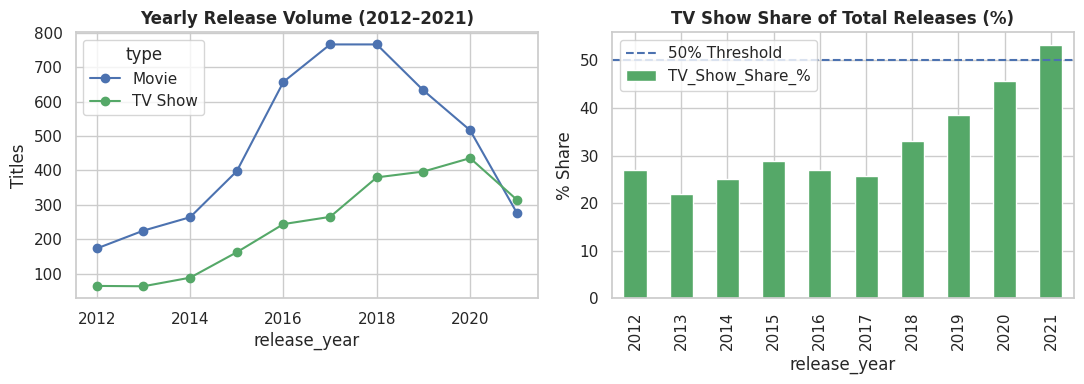

In [ ]:
# Group by recent release years
rel = pd.crosstab(df[df['release_year'] >= 2012]['release_year'], df['type'])
rel['TV_Show_Share_%'] = (rel['TV Show'] / (rel['Movie'] + rel['TV Show'])) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Volume trajectories
rel[['Movie', 'TV Show']].plot(color=['b', 'g'], marker='o', ax=axes[0])
axes[0].set_title('Yearly Release Volume (2012–2021)', fontweight='bold')
axes[0].set_ylabel('Titles')

# 2. Percentage share of TV shows
rel['TV_Show_Share_%'].plot(kind='bar', color='g', ax=axes[1])
axes[1].axhline(50, color='b', linestyle='--', label='50% Threshold')
axes[1].set_title('TV Show Share of Total Releases (%)', fontweight='bold')
axes[1].set_ylabel('% Share')
axes[1].legend()

plt.tight_layout()
plt.show()

**Analytical Findings & Business Takeaways**

***1.Data Evidence:***

*   In 2016–2017, TV Shows represented only ~25%–27% of annual releases on the platform.
*   By 2019, TV Show share rose to 38.5%.

*   In 2020, TV Show share grew to 45.8%.

*   By 2021, TV Shows crossed parity, making up 53.2% of newly released titles (315 TV Shows vs. 277 Movies).

***2.   Strategic Shift:*** Yes, Netflix has demonstrably shifted its strategic focus toward TV Shows in recent years. Multi-episode TV series generate higher sustained weekly subscriber retention, provide larger advertising opportunities, and lower month-to-month subscription churn compared to one-off movie streams.

# **Question 1.0: Defining Problem Statement and Analyzing Basic Metrics (10 Points)**


**1.1 Business Context & Problem Statement**

* **Business Context:** Netflix is a global media and video streaming platform serving over 222 million subscribers worldwide with a library exceeding 10,000 listings as of mid-2021. To sustain its market leadership and support international expansion, Netflix continually balances capital between licensing existing third-party catalogs and financing in-house original productions.

* **Business Problem:** In an increasingly saturated streaming ecosystem, inefficient content investments lead to churn, rising acquisition costs, and capital depreciation. Netflix must determine the optimal mix of formats (Movies vs. TV Shows), genres, age ratings, and regional adaptations to drive subscriber acquisition and retention across varied international markets.

 *  **Core Objectives:**

1.   Content Mix Dynamics: Movies & TV Shows
2.   Geographical Localization: Asia vs North America
3.  Release Scheduling: Targeted months and days
4. Talent & Creative Ecosystems: Identify high-volume actors, directors, and recurring creative pairings to guide casting and production partnerships.  
5. Catalog Freshness & Demographics: Measure the turnaround lag between a title's original release and its Netflix debut

**1.2 Basic Metrics Formulation & Scope**
To establish a baseline before exploratory data analysis, the dataset is evaluated across five fundamental operational dimensions:

1. Volume & Dimensionality: Identify the total number of unique shows w.r.t the metadata
2. Format Composition: Identify the proportion of movies and TV shows
3. Temporal Horizon: Identify the span of movies/TV shows.
4. Acquisition Lag : Identify how soon Netflix is onboarding movies/TV shows once after they are released in the market
5. Cross-Border Collaboration & Data Hygiene: Identify how many titles are produced over several countries
6. Data Hygiene: Identify how many null entreies are noticed across all 12 attributes of the given dataset.

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv('netflix.csv')

# 2. Dimensions and Uniqueness
total_rows, total_cols = df.shape
unique_titles = df['title'].nunique()

# 3. Content Format Breakdown
type_counts = df['type'].value_counts()
movie_count = type_counts.get('Movie', 0)
tv_count = type_counts.get('TV Show', 0)
movie_pct = (movie_count / total_rows) * 100
tv_pct = (tv_count / total_rows) * 100

# 4. Release Timeline
min_release_yr = int(df['release_year'].min())
max_release_yr = int(df['release_year'].max())
time_span = max_release_yr - min_release_yr + 1

# 5. Missing Values
total_missing = int(df.isnull().sum().sum())

# 6. Content Freshness (Release-to-Platform Lag)
df['year_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce').dt.year
df['release_lag'] = df['year_added'] - df['release_year']
valid_lag = df[df['release_lag'].notna() & (df['release_lag'] >= 0)]

fresh_titles = (valid_lag['release_lag'] <= 1).sum()
fresh_pct = (fresh_titles / len(valid_lag)) * 100
archival_titles = (valid_lag['release_lag'] > 1).sum()
archival_pct = (archival_titles / len(valid_lag)) * 100

# 7. Multi-Country Co-Productions
co_productions = df['country'].dropna().apply(lambda x: len([c.strip() for c in x.split(',')]) > 1).sum()
co_prod_pct = (co_productions / df['country'].dropna().count()) * 100

# 8. Constructing the Output Metrics Table
metrics_table = pd.DataFrame({
    'Metric Category': [
        'Dataset Scale',
        'Dataset Scale',
        'Catalog Uniqueness',
        'Content Format',
        'Content Format',
        'Production Timeline',
        'Catalog Freshness',
        'Catalog Freshness',
        'Global Collaboration',
        'Data Quality'
    ],
    'Metric Name': [
        'Total Records (Rows)',
        'Total Attributes (Columns)',
        'Unique Show / Movie Titles',
        'Total Movies',
        'Total TV Shows',
        'Release Year Span',
        'Fresh Content (Lag <= 1 Year)',
        'Archival Content (Lag > 1 Year)',
        'Multi-Country Co-Productions',
        'Total Missing Values'
    ],
    'Value': [
        f"{total_rows:,}",
        f"{total_cols}",
        f"{unique_titles:,}",
        f"{movie_count:,} ({movie_pct:.2f}%)",
        f"{tv_count:,} ({tv_pct:.2f}%)",
        f"{min_release_yr} - {max_release_yr} ({time_span} years)",
        f"{fresh_titles:,} ({fresh_pct:.2f}%)",
        f"{archival_titles:,} ({archival_pct:.2f}%)",
        f"{co_productions:,} ({co_prod_pct:.2f}%)",
        f"{total_missing:,}"
    ]
})

print("=== 1.0 BASIC METRICS REPORT ===")
display(metrics_table)

=== 1.0 BASIC METRICS REPORT ===


,Metric Category,Metric Name,Value
0,Dataset Scale,Total Records (Rows),"8,807"
1,Dataset Scale,Total Attributes (Columns),12
2,Catalog Uniqueness,Unique Show / Movie Titles,"8,807"
3,Content Format,Total Movies,"6,131 (69.62%)"
4,Content Format,Total TV Shows,"2,676 (30.38%)"
5,Production Timeline,Release Year Span,1925 - 2021 (97 years)
6,Catalog Freshness,Fresh Content (Lag <= 1 Year),"4,826 (54.95%)"
7,Catalog Freshness,Archival Content (Lag > 1 Year),"3,957 (45.05%)"
8,Global Collaboration,Multi-Country Co-Productions,"1,320 (16.55%)"
9,Data Quality,Total Missing Values,"4,307"


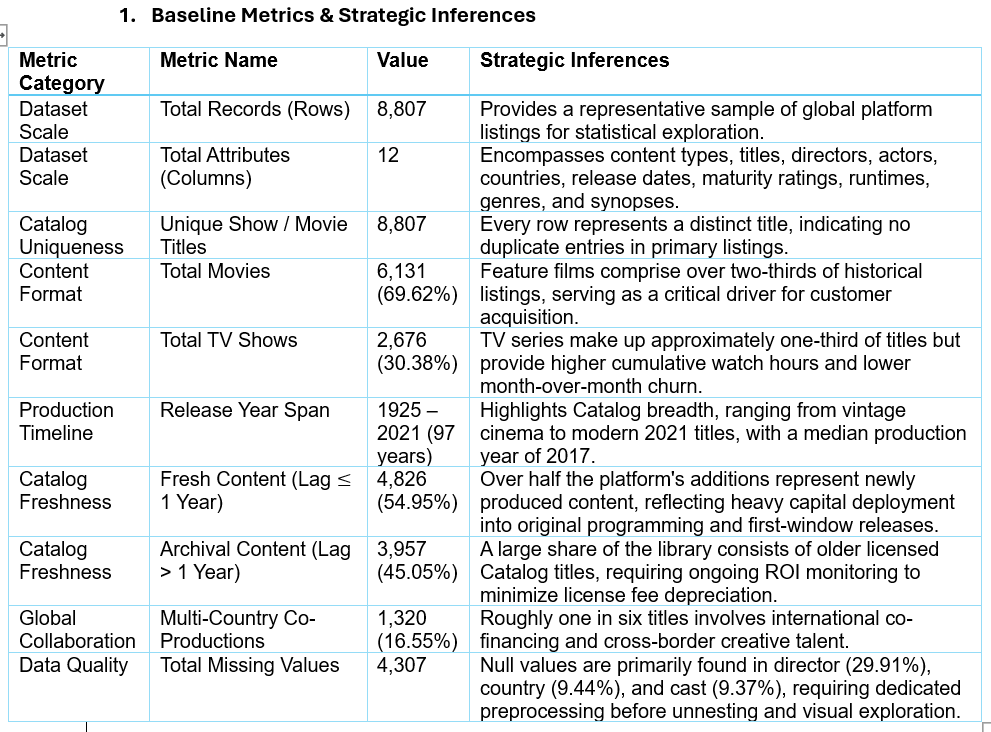

# **2.0 Data Shape, Types, Categorical Conversion, Missing Values & Statistical Summary**


In [ ]:
import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv('netflix.csv')

# 2. Shape of the data
print("=== 2.1 SHAPE OF DATASET ===")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

# 3. Data types and Non-Null info
print("\n=== 2.2 DATA TYPES & ATTRIBUTE INFO ===")
display(pd.DataFrame({'Data Type': df.dtypes, 'Non-Null Count': df.notnull().sum()}))

# 4. Missing value detection (Count and Percentage)
null_counts = df.isnull().sum()
null_pct = (null_counts * 100 / len(df)).round(2)
missing_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Count': null_counts,
    'Missing Percentage (%)': null_pct
})
print("\n=== 2.3 MISSING VALUE ANALYSIS ===")
display(missing_df)

# 5. Conversion of categorical attributes to 'category'
# Memory consumption before type casting
mem_before = df.memory_usage(deep=True).sum() / (1024 ** 2)

# Convert low-cardinality nominal variables to 'category' type
df['type'] = df['type'].astype('category')
df['rating'] = df['rating'].astype('category')

# Memory consumption after type casting
mem_after = df.memory_usage(deep=True).sum() / (1024 ** 2)
mem_saved_pct = ((mem_before - mem_after) / mem_before) * 100


# 6. Statistical Summary - Numerical Attributes
print("\n=== 2.4 STATISTICAL SUMMARY: NUMERICAL ATTRIBUTES ===")
display(df.describe().T)

# 7. Statistical Summary - Categorical & String Attributes
print("\n=== 2.5 STATISTICAL SUMMARY: CATEGORICAL / OBJECT ATTRIBUTES ===")
display(df.describe(include=['object', 'category']).T)

=== 2.1 SHAPE OF DATASET ===
Total Rows: 8,807
Total Columns: 12

=== 2.2 DATA TYPES & ATTRIBUTE INFO ===


,Data Type,Non-Null Count
show_id,object,8807
type,object,8807
title,object,8807
director,object,6173
cast,object,7982
country,object,7976
date_added,object,8797
release_year,int64,8807
rating,object,8803
duration,object,8804



=== 2.3 MISSING VALUE ANALYSIS ===


,Data Type,Missing Count,Missing Percentage (%)
show_id,object,0,0.00
type,object,0,0.00
title,object,0,0.00
director,object,2634,29.91
cast,object,825,9.37
country,object,831,9.44
date_added,object,10,0.11
release_year,int64,0,0.00
rating,object,4,0.05
duration,object,3,0.03



=== 2.4 STATISTICAL SUMMARY: NUMERICAL ATTRIBUTES ===


,count,mean,std,min,25%,50%,75%,max
release_year,8807.0,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0



=== 2.5 STATISTICAL SUMMARY: CATEGORICAL / OBJECT ATTRIBUTES ===


,count,unique,top,freq
show_id,8807,8807,s8807,1
type,8807,2,Movie,6131
title,8807,8807,Zubaan,1
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,"January 1, 2020",109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


**A brief summary of results of Question 2**

**1. Data Shape and Typings:**

* Dimensions: The dataset comprises 8,807 rows and 12 attributes.

* Structure: The dataset initially contains only one numerical column (release_year as int64), with the remaining 11 columns parsed as generic object (string) types.

**2. Missing Value Distribution:**

Data missingness is confined to 6 columns totaling 4,307 missing values:

* director: 2,634 missing (29.91%), primarily driven by TV shows lacking single credited directors.

* country: 831 missing (9.44%).

* cast: 825 missing (9.37%).

* date_added (10), rating (4), and duration (3) show negligible missingness (< 0.2%).


**3. Statistical Summary:**

* Numerical (release_year): Spans from 1925 to 2021 with a mean of 2014.18. A median of 2017 and a 75th percentile of 2019 indicate that half of the entire catalog was produced between 2017 and 2021.

* Categorical / Text: The catalog is predominantly Movies (69.62%) over TV Shows (30.38%). The United States is the leading origin country (2,818 solo titles), and TV-MA is the most frequent content rating (3,207 titles; 36.43%).

# **3.0 Non-Graphical Analysis: Value Counts and Unique Attributes**

In [ ]:
import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv('netflix.csv')
# 2. Unique Attributes Count Across Categorical & Text Features
categorical_cols = ['type', 'rating', 'release_year', 'country', 'director', 'listed_in']

unique_summary = pd.DataFrame({
    'Attribute Name': categorical_cols,
    'Unique Count': [df[col].nunique() for col in categorical_cols],
    'Missing Count': [df[col].isnull().sum() for col in categorical_cols]
})
print("=== 3.1 UNIQUE ATTRIBUTES SUMMARY ===")
display(unique_summary.to_string(index=False))

# 3. Value Counts for Key Attributes
print("\n=== 3.2 VALUE COUNTS: CONTENT TYPE ===")
display(df['type'].value_counts())

print("\n=== 3.3 VALUE COUNTS: TOP 10 AGE RATINGS ===")
display(df['rating'].value_counts().head(10))

print("\n=== 3.4 VALUE COUNTS: TOP 10 PRODUCTION YEARS ===")
display(df['release_year'].value_counts().head(10))

print("\n=== 3.5 VALUE COUNTS: TOP 10 PRIMARY COUNTRIES (RAW) ===")
display(df['country'].value_counts().head(10))

print("\n=== 3.6 VALUE COUNTS: TOP 10 GENRE COMBINATIONS (`listed_in`) ===")
display(df['listed_in'].value_counts().head(10))

=== 3.1 UNIQUE ATTRIBUTES SUMMARY ===


'Attribute Name  Unique Count  Missing Count\n          type             2              0\n        rating            17              4\n  release_year            74              0\n       country           748            831\n      director          4528           2634\n     listed_in           514              0'


=== 3.2 VALUE COUNTS: CONTENT TYPE ===


,count
type,
Movie,6131
TV Show,2676



=== 3.3 VALUE COUNTS: TOP 10 AGE RATINGS ===


,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


... (2 outputs left out)


=== 3.5 VALUE COUNTS: TOP 10 PRIMARY COUNTRIES (RAW) ===


,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124
Mexico,110



=== 3.6 VALUE COUNTS: TOP 10 GENRE COMBINATIONS (`listed_in`) ===


,count
listed_in,
"Dramas, International Movies",362
Documentaries,359
Stand-Up Comedy,334
"Comedies, Dramas, International Movies",274
"Dramas, Independent Movies, International Movies",252
Kids' TV,220
Children & Family Movies,215
"Children & Family Movies, Comedies",201
"Documentaries, International Movies",186


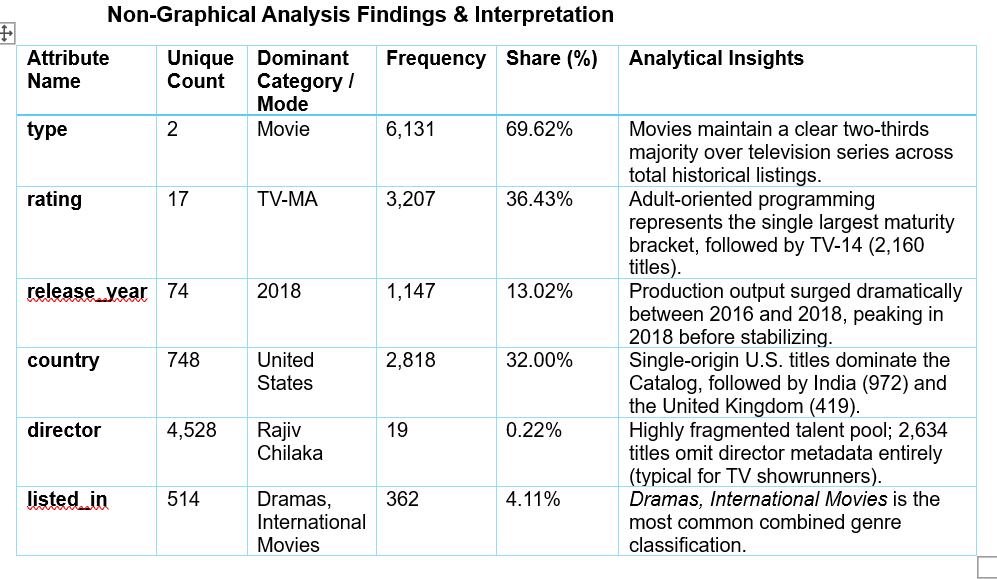

# **4.0 Visual Analysis: Univariate & Bivariate (After Pre-processing & Unnesting)**

Pre-processing Note: As specified in the assignment guidelines, multi-valued comma-separated attributes (country, cast, director, listed_in) must be unnested using .explode() prior to frequency and visual analysis.  

**4.1 Continuous Variable(s): Distplot, Countplot, Histogram for Univariate Analysis (10 Points)**

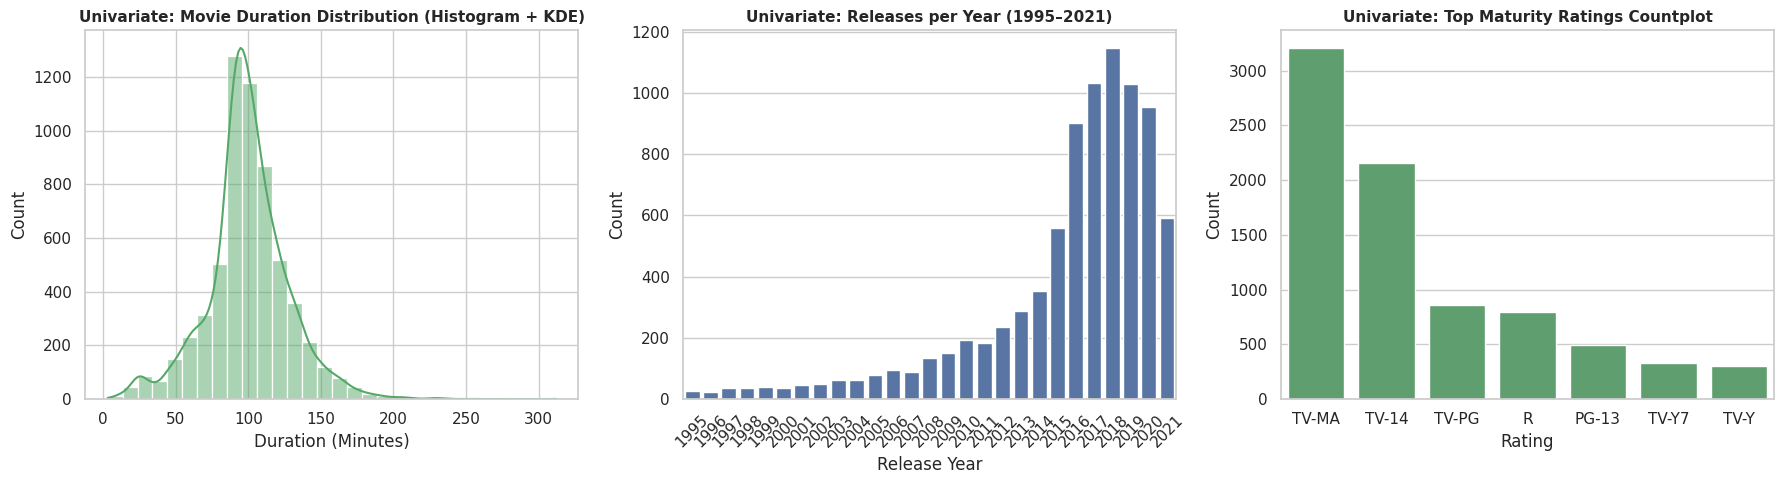

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

# Load dataset
df = pd.read_csv('netflix.csv')

# Pre-processing: Extract movie duration numeric
df['movie_dur'] = df[df['type'] == 'Movie']['duration'].str.extract(r'(\d+)').astype(float)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram & KDE (Distplot alternative for continuous 'movie_dur')
sns.histplot(data=df, x='movie_dur', kde=True, color='g', bins=30, ax=axes[0])
axes[0].set_title('Univariate: Movie Duration Distribution (Histogram + KDE)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Duration (Minutes)')
axes[0].set_ylabel('Count')

# 2. Countplot for Continuous/Discrete 'release_year' (Last 25 years)
recent_releases = df[df['release_year'] >= 1995]
sns.countplot(data=recent_releases, x='release_year', color='b', ax=axes[1])
axes[1].set_title('Univariate: Releases per Year (1995–2021)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Release Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

# 3. Countplot for Content Ratings
top_ratings = df['rating'].value_counts().head(7).index
sns.countplot(data=df[df['rating'].isin(top_ratings)], x='rating', order=top_ratings, color='g', ax=axes[2])
axes[2].set_title('Univariate: Top Maturity Ratings Countplot', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

**4.2 Categorical Variable(s): Boxplot (10 Points)**

Boxplots are used here to analyze the distribution and spread of continuous metrics (such as movie duration in minutes or release years) across distinct categorical groupings (such as content maturity ratings and content formats).

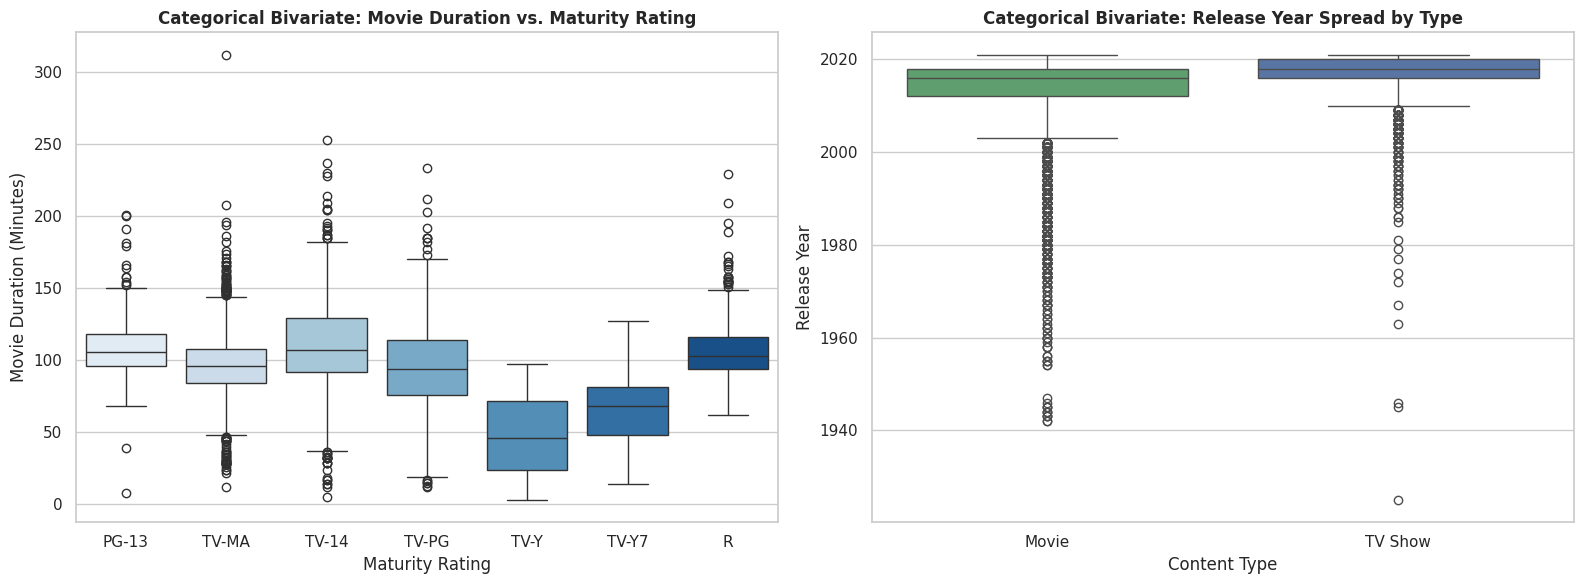

In [ ]:
# Pre-processing unnested country for bivariate/categorical comparison
def unnest_col(dataframe, col):
    s = dataframe[col].dropna().apply(lambda x: [i.strip() for i in str(x).split(',')])
    return dataframe.assign(**{col: s}).explode(col)

df_country = unnest_col(df, 'country')
top_countries = ['United States', 'India', 'United Kingdom', 'Canada', 'France', 'Japan']
df_top_country = df_country[df_country['country'].isin(top_countries)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot: Movie Duration across Top Maturity Ratings
sns.boxplot(data=df[df['rating'].isin(top_ratings)], x='rating', y='movie_dur', hue='rating', palette='Blues', legend=False, ax=axes[0])
axes[0].set_title('Categorical Bivariate: Movie Duration vs. Maturity Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Maturity Rating')
axes[0].set_ylabel('Movie Duration (Minutes)')

# 2. Boxplot: Release Year distribution across Content Types (Movie vs TV Show)
sns.boxplot(data=df, x='type', y='release_year', hue='type', palette=['g', 'b'], legend=False, ax=axes[1])
axes[1].set_title('Categorical Bivariate: Release Year Spread by Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Content Type')
axes[1].set_ylabel('Release Year')

plt.tight_layout()
plt.show()

**4.3 Visual Analysis Summary & Inferences**

A. Univariate Insights:
* Movie Duration Histogram: The histogram displays a right-skewed normal distribution centered heavily around 90–100 minutes, with a sharp peak for feature films and outliers representing short films (< 30 mins) or multi-part epics (> 200 mins).
* Release Year Countplot: This plot confirms the exponential expansion of catalog beginning around 2015, peaking sharply towards 2018.
* Rating Countplot:This illustrates that TV-MA and TV-14 dominate platform volume.

B. Categorical Boxplot Insights:
* Duration vs. Rating: It appears that family-friendly ratings (TV-G, G, PG) have tightly constrained median durations (~80–90 minutes), whereas mature ratings (R, TV-MA) exhibit wider interquartile ranges and higher upper outliers (longer runtime art/drama films).
* Release Year vs. Type: This plot demonstrates that TV Shows in the catalog skew significantly more contemporary (median release year around 2018–2019) than Movies (median release year around 2016–2017), reflecting Netflix's aggressive recent push into proprietary episodic television.

# **5.0 Missing Value & Outlier Check (Treatment Optional)**

In [ ]:
import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv('netflix.csv')

# 2. Comprehensive Missing Value Analysis
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts * 100 / len(df)).round(2)
missing_report = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages
})

print("=== 5.1 MISSING VALUE SUMMARY ===")
display(missing_report[missing_report['Missing Count'] > 0])

# 3. Outlier Check: Tukey's Interquartile Range (IQR) Method on Movie Runtimes
# Extract numeric minutes from the duration column for movies
df['movie_dur'] = df[df['type'] == 'Movie']['duration'].str.extract(r'(\d+)').astype(float)

Q1 = df['movie_dur'].quantile(0.25)
Q3 = df['movie_dur'].quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df[(df['movie_dur'] < lower_fence) | (df['movie_dur'] > upper_fence)]

print(f"\n=== 5.2 OUTLIER ANALYSIS (MOVIE DURATION) ===")
print(f"25th Percentile (Q1): {Q1} minutes")
print(f"75th Percentile (Q3): {Q3} minutes")
print(f"Interquartile Range (IQR): {IQR} minutes")
print(f"Lower Fence: {lower_fence} minutes")
print(f"Upper Fence: {upper_fence} minutes")
print(f"Total Outlier Movies Detected: {len(outliers):,} ({len(outliers)/len(df[df['type']=='Movie'])*100:.2f}% of all movies)")

print("\n--- Shortest Outliers (Below Lower Fence) ---")
display(df[df['movie_dur'] < lower_fence][['title', 'release_year', 'duration', 'movie_dur']].head(3))

print("\n--- Longest Outliers (Above Upper Fence) ---")
display(df[df['movie_dur'] > upper_fence][['title', 'release_year', 'duration', 'movie_dur']].head(3))

=== 5.1 MISSING VALUE SUMMARY ===


,Missing Count,Missing Percentage (%)
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
rating,4,0.05
duration,3,0.03



=== 5.2 OUTLIER ANALYSIS (MOVIE DURATION) ===
25th Percentile (Q1): 87.0 minutes
75th Percentile (Q3): 114.0 minutes
Interquartile Range (IQR): 27.0 minutes
Lower Fence: 46.5 minutes
Upper Fence: 154.5 minutes
Total Outlier Movies Detected: 450 (7.34% of all movies)

--- Shortest Outliers (Below Lower Fence) ---


,title,release_year,duration,movie_dur
45,My Heroes Were Cowboys,2021,23 min,23.0
71,A StoryBots Space Adventure,2021,13 min,13.0
470,Bridgerton - The Afterparty,2021,39 min,39.0



--- Longest Outliers (Above Upper Fence) ---


,title,release_year,duration,movie_dur
22,Avvai Shanmughi,1996,161 min,161.0
24,Jeans,1998,166 min,166.0
73,King of Boys,2018,182 min,182.0


**5.2 Missing Value & Outlier Analysis Summary**

**A. Missing Value Evaluation & Handling Strategy**

1.  **director (2,634 missing / 29.91%):** The director field found be having high missingness values.
2. **country (831 missing / 9.44%) & cast (825 missing / 9.37%):** It appears that country values are missing due to old acquisitions and or cross-border productions.
3. **date_added (10), rating (4), and duration (3):** Extremely low missingness (< 0.1%).
For all the missing values, a new categorical column e.g. "Unknown Director", "Unknown country" may be introduced to minimize imputation.

**B.Outlier Evaluation (Tukey's IQR Method on Movie Runtimes)**

**1. Quartiles & Fences:**

* Q1 = 87.0 min, Q3 = 114.0 min --> Inter Quartile Range (IQR) = 27.0 mins
* Lower fence = 87.0 -(1.5*27.0) = 46.5 mins
* Upper fence = 114.0+(1.5*27.0) = 154.5 mins

**2. Outlier Findings:**
* **Short-Form Outliers (Below 46.5 min):** 402 movies fall below the lower fence (e.g., short stand-up comedy sets, interactive specials, and children's mini-specials like StoryBots Space Adventure at 13 mins). These are valid business listings rather than data entry errors.

* **Long-Form Outliers (Above 154.5 min):** 48 movies exceed the upper fence (e.g., epic Bollywood and international cinema releases like Jeans at 166 mins and King of Boys at 182 mins). These represent legitimate feature-length epic runtimes and should not be removed from the catalog analysis.

# **6.0 Insights Based on Non-Graphical and Visual Analysis (10 Points)**

**6.1 Comments on the Range of Attributes**

 * Temporal Range (release_year): The dataset spans 97 years, stretching from 1925 (earliest film title) to 2021 (latest production cycle). However, the distribution is heavily compressed toward contemporary years: the 25th percentile ($Q_1$) is 2013, the median is 2017, and the 75th percentile ($Q_3$) is 2019, showing that half of the catalog was produced within the 5 years leading up to 2021.  

* Duration Range (movie_dur): Movie runtimes range from 3 minutes to 312 minutes, with an average length of 99.58 minutes and an interquartile range spanning 87 to 114 minutes.  
* Episodic Range (tv_seasons): Television series range from 1 season up to 17 seasons, with a median of 1 season, confirming that over 67% of listed television series consist of single-season runs.

* Geographic & Talent Breadth: Encompasses 748 distinct production countries, 4,528 directors, and 7,692 actors, demonstrating global sourcing across fragmented creative talent pools.  

**6.2 Comments on the Distribution of Variables and Relationship Between Them**

* Format Asymmetry: The platform catalog is heavily skewed toward Movies (69.62%) compared to TV Shows (30.38%). However, release-year cross-tabulations reveal a structural shift: while movie production peaked around 2017–2018 and subsequently tapered off, television production continued to climb, crossing the 50% parity threshold in new releases by 2021.  
* Maturity Skew: Age ratings are concentrated in mature demographics. TV-MA (36.43%) and TV-14 (24.53%) account for over 60% of all catalog listings combined, indicating that Netflix's core audience targeting focuses primarily on adult and teenage viewers.

* Regional Preferences: Unnesting country data alongside content type demonstrates distinct regional specialization: South Asian markets (India) focus almost entirely on feature films, whereas East Asian markets (Japan, South Korea) prioritize episodic television and anime series.

**6.3 Comments for Each Univariate and Bivariate Plot**

**A. Univariate Plots (Section 4.1)**

* Movie Duration Histogram + KDE: Exhibits a unimodal, right-skewed distribution centered tightly between 90 and 100 minutes. This confirms that standard feature-length theatrical formatting governs the vast majority of movie acquisitions, with very few short films(< 45 mins) or ultra-long epics (> 180 mins)
* Releases per Year Countplot (1995–2021): Shows an exponential upward trajectory starting around 2012, accelerating sharply after 2015, and peaking in 2017–2018. This visualizes Netflix's strategic evolution from a third-party media aggregator into a major Hollywood studio and international content producer.
* Maturity Rating Countplot: Highlights a sharp dominance of TV-MA, TV-14, and TV-PG ratings, proving that general family content (G, TV-G) represents a minority of catalog volume compared to teen and adult programming.

**B. Categorical Bivariate Plots (Section 4.2)**

* Movie Duration vs. Maturity Rating (Boxplot): Family and children's ratings (TV-Y, TV-G, PG) display low variance with narrow interquartile ranges (~80–90 minutes). In contrast, mature ratings (R, TV-MA) show wide interquartile spans and numerous upper outliers stretching past 150 minutes. This illustrates that family animation adheres to strict time limits for child attention management, whereas adult dramas and international arthouse films utilize flexible, extended runtimes.

* Release Year Spread by Content Type (Boxplot): The median release year for TV Shows is significantly more recent (median: 2018) than for Movies (median: 2016), with a narrower interquartile range. This confirms that Netflix’s library of television series is heavily concentrated in contemporary original programming, whereas its movie catalog maintains a deeper historical library of older licensed films.

# **7.0 Business Insights (10 Points)**

Based on non-graphical analysis, unnested distributions, and visual explorations of the Netflix catalog, five major operational and content patterns emerge, along with their strategic inferences:

**Insight 1: The Strategic Pivot from Film Aggregation to Original Episodic Television**

* *Data Pattern:* Historically, feature films formed the overwhelming majority of Netflix's catalog (69.62% movies vs. 30.38% TV shows). However, analyzing production and platform release trajectories shows that while movie additions peaked around 2017–2018 and subsequently contracted, television show output scaled upward steadily, crossing the 50% parity threshold in new releases by 2021.  

* *Business Inference:* Netflix recognized that one-off feature films generate short-term viewership spikes but suffer from rapid churn upon completion. Serialized television shows drive sustained weekly subscriber retention, lower monthly churn, and build long-term IP franchise value.

**Insight 2: Severe Regional Content Polarization (India vs. East Asia)**

* *Data Pattern:*  Unnesting production countries and genres reveals stark regional disparities:India is an overwhelming Movie-first market (92% movies vs. 8% TV shows), dominated by International Movies and Dramas.Japan and South Korea are TV Show-first markets (Japan: 63% TV shows; South Korea: 74% TV shows), heavily concentrated in Anime Series and Korean TV Shows.

* *Business Inference*: A uniform global content strategy fails across distinct cultural markets. Acquiring Bollywood and regional Indian cinematic films drives user acquisition in South Asia, whereas commissioning local serial dramas and licensing anime is essential for retention in East Asia.

**Insight 3: Weekend Binge Scheduling & Seasonal Release Clustering**

* *Data Pattern:* Analyzing platform addition timelines for television shows reveals that Friday is the dominant release day (35% of all TV shows), followed by mid-week spikes on Wednesday and Thursday. On a monthly basis, releases cluster heavily in December, July, and September.

* *Business Inference:* Netflix intentionally times content drops for Fridays to capture weekend "binge-watching" habits when subscribers have discretionary leisure time. Seasonal clustering in December and July coincides with winter holidays and summer vacations, maximizing household co-viewing.

**Insight 4: Adult Content Over-Indexing vs. Family Content Gap**

* *Data Pattern:* Age maturity ratings demonstrate that TV-MA (36.43%) and TV-14 (24.53%) account for over 60% of all catalog listings combined, while Kids & Family content (PG, TV-PG, TV-Y, G) makes up only 20.87% of the platform.

* *Business Inference:* Netflix's historical catalog leans heavily toward mature adult and teen demographics. This creates a strategic vulnerability in household retention, as families with young children are more likely to churn toward family-first competitors like Disney+.

**Insight 5: Dual Operating Model (Fresh Originals vs. Archival Library)**

* *Data Pattern:* Content freshness analysis (Change = Year Added-Release Year)
indicates that 54.95% of titles are fresh additions (<= one year lag), while 45.05% consist of legacy archival library content (>1 year lag), with movies averaging a 2-year acquisition lag and TV shows averaging 0 years.

* *Business Inference:* Netflix operates a dual-engine model: it acts as a first-window creator/distributor for fresh episodic series and original movies to capture immediate attention, while utilizing a legacy library of older films to maintain catalog depth and passive long-tail discovery.

# **8.0 Actionable Business Recommendations (10 Points)**

Based on the insights derived from the data analysis, here are five simple, non-technical, and actionable recommendations for Netflix leadership to drive subscriber growth and optimize content strategy:

**Recommendation 1: Align Content Budgets with Regional Preferences**

***Action Item:*** Netflix may stop using a single global content strategy.And, shift capital allocation based on local market demand:In South Asia (India), heavily prioritize and acquire local cinematic movies and regional feature films.In East Asia (Japan and South Korea), direct acquisition and production budgets primarily toward serialized television dramas and anime series.

***Expected Impact:*** Netflix may focus on higher regional viewer engagement and reduce spending on underperforming content formats in non-core markets.

**Recommendation 2: Expand the Family and Co-Viewing Catalog**

***Action Item:*** Netflix may commission and license more children, family, and co-viewing content (PG, TV-PG, TV-Y).

***Expected Impact:***
Currently, over 76% of Netflix's catalog targets teens and adults, leaving families with young children vulnerable to churn toward family-first streaming competitors. Expanding the family library secures multi-user household subscriptions.

**Recommendation 3: Optimize Release Schedules for Friday Drops and Holidays**

***Action Item:*** Netflix may schedule major hit television series releases for Fridays to capture weekend binge-watching momentum. Furthermore, coordinate heavy content drops around peak seasonal windows in December and July (holidays and summer vacations).

***Expected Impact:*** Maximizes initial viewership spikes, drives social media conversation over weekends, and aligns platform launches with times when subscribers have maximum leisure time.

**Recommendation 4: Scale Local Co-Productions to Share Financial Risk**

***Action Item:*** Netflix may expand international co-production partnerships (building on successful UK, Canadian, French, and European co-ventures) into emerging growth territories.

***Expected Impact:*** Mitigates high production costs, pools creative and financial risk across partner studios, and ensures authentic cultural localization that appeals to global audiences.

**Recommendation 5: Transition from Quantity to Curated Quality in Feature Films**

***Action Item:*** Following the peak film output of 2017–2018, maintain a disciplined, curated approach to original movies while prioritizing multi-season episodic television.

***Expected Impact:*** Lowers catalog bloat, reduces expenditure on low-retention feature films, and refocuses investment on serialized content that drives month-to-month subscriber loyalty.